In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:,.2f}'.format
FICHIER = 'archive/CAR DETAILS FROM CAR DEKHO.csv'

df = pd.read_csv(FICHIER)
df.columns = df.columns.str.strip().str.lower()
df = df[['name', 'year', 'selling_price', 'km_driven', 'fuel']]
print('Fichier utilisé :', FICHIER)
print('Dimensions :', df.shape)
df.head()

Fichier utilisé : archive/CAR DETAILS FROM CAR DEKHO.csv
Dimensions : (4340, 5)


,name,year,selling_price,km_driven,fuel
0,Maruti 800 AC,2007,60000,70000,Petrol
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel
3,Datsun RediGO T Option,2017,250000,46000,Petrol
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel


In [5]:
print('--- Types des colonnes ---')
print(df.dtypes, '\n')

print('--- Valeurs manquantes par colonne ---')
print(df.isna().sum(), '\n')

print('Doublons exacts :', df.duplicated().sum())

print('\n--- Valeurs suspectes ---')
print('Prix <= 0           :', (df['selling_price'] <= 0).sum())
print('Kilométrage <= 0    :', (df['km_driven'] <= 0).sum())
print('Année > 2026 ou < 1980 :', ((df['year'] > 2026) | (df['year'] < 1980)).sum())
print('Kilométrage > 500 000  :', (df['km_driven'] > 500_000).sum())
print('\nCarburants présents :', df['fuel'].value_counts().to_dict())

--- Types des colonnes ---
name               str
year             int64
selling_price    int64
km_driven        int64
fuel               str
dtype: object 

--- Valeurs manquantes par colonne ---
name             0
year             0
selling_price    0
km_driven        0
fuel             0
dtype: int64 

Doublons exacts : 767

--- Valeurs suspectes ---
Prix <= 0           : 0
Kilométrage <= 0    : 0
Année > 2026 ou < 1980 : 0
Kilométrage > 500 000  : 3

Carburants présents : {'Diesel': 2153, 'Petrol': 2123, 'CNG': 40, 'LPG': 23, 'Electric': 1}


In [6]:
n0 = len(df)
df = df.drop_duplicates().dropna()
df = df[(df['selling_price'] > 0) & (df['km_driven'] > 0) & df['year'].between(1980, 2026)]
n1 = len(df)

def filtre_iqr(data, col):
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    return data[data[col].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)]

for col in ['selling_price', 'km_driven']:
    df = filtre_iqr(df, col)
n2 = len(df)

print(f'Lignes initiales                   : {n0}')
print(f'Après doublons / manquants / invalides : {n1}  (-{n0 - n1})')
print(f'Après filtrage IQR (outliers)      : {n2}  (-{n1 - n2})')

Lignes initiales                   : 4340
Après doublons / manquants / invalides : 3573  (-767)
Après filtrage IQR (outliers)      : 3283  (-290)


In [7]:
ANNEE_ACTUELLE = 2026

df = df.copy()
df['age'] = (ANNEE_ACTUELLE - df['year']).clip(lower=1)
df['km_an'] = df['km_driven'] / df['age']
df['marque'] = df['name'].str.split().str[0]

print((ANNEE_ACTUELLE - df['year'] <= 0).sum(), 'véhicule(s) avec âge 0 ramené(s) à 1 an')
df[['name', 'marque', 'year', 'age', 'km_driven', 'km_an', 'selling_price']].head()

0 véhicule(s) avec âge 0 ramené(s) à 1 an


,name,marque,year,age,km_driven,km_an,selling_price
0,Maruti 800 AC,Maruti,2007,19,70000,"3,684.21",60000
1,Maruti Wagon R LXI Minor,Maruti,2007,19,50000,"2,631.58",135000
2,Hyundai Verna 1.6 SX,Hyundai,2012,14,100000,"7,142.86",600000
3,Datsun RediGO T Option,Datsun,2017,9,46000,"5,111.11",250000
4,Honda Amaze VX i-DTEC,Honda,2014,12,141000,"11,750.00",450000


In [8]:
prix = df['selling_price']
print('--- Prix de revente ---')
print(prix.describe())
print('Médiane :', prix.median())
print('Écart interquartile (IQR) :', prix.quantile(0.75) - prix.quantile(0.25))
print('Asymétrie (skewness) :', round(prix.skew(), 2))

print('\n--- Répartition par carburant (%) ---')
print((df['fuel'].value_counts(normalize=True) * 100).round(1))

print('\n--- Prix médian par carburant ---')
print(df.groupby('fuel')['selling_price'].agg(['count', 'median']))

print('\n--- 10 marques les plus fréquentes : prix médian ---')
top = df['marque'].value_counts().head(10).index
print(df[df['marque'].isin(top)].groupby('marque')['selling_price'].agg(['count', 'median']).sort_values('median'))

--- Prix de revente ---
count       3,283.00
mean      392,989.39
std       253,465.39
min        20,000.00
25%       195,000.00
50%       330,000.00
75%       550,000.00
max     1,200,000.00
Name: selling_price, dtype: float64
Médiane : 330000.0
Écart interquartile (IQR) : 355000.0
Asymétrie (skewness) : 0.87

--- Répartition par carburant (%) ---
fuel
Petrol     51.30
Diesel     46.90
CNG         1.10
LPG         0.60
Electric    0.00
Name: proportion, dtype: float64

--- Prix médian par carburant ---
          count     median
fuel                      
CNG          37 229,999.00
Diesel     1540 450,000.00
Electric      1 310,000.00
LPG          21 180,000.00
Petrol     1684 260,000.00

--- 10 marques les plus fréquentes : prix médian ---
            count     median
marque                      
Tata          289 190,000.00
Chevrolet     147 195,000.00
Maruti       1052 275,000.00
Hyundai       619 340,000.00
Renault       108 362,500.00
Volkswagen     90 400,000.00
Ford          20

Asymétrie avant : 0.87
Asymétrie après : -0.48


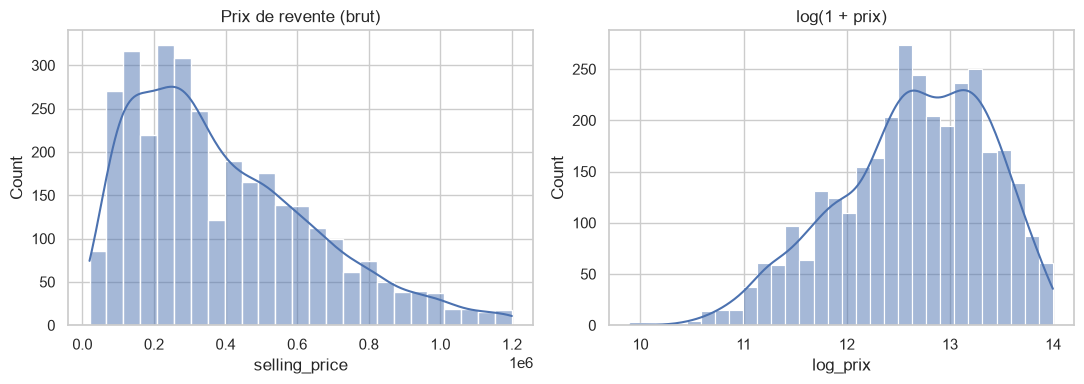

In [9]:
df['log_prix'] = np.log1p(df['selling_price'])
print('Asymétrie avant :', round(df['selling_price'].skew(), 2))
print('Asymétrie après :', round(df['log_prix'].skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['selling_price'], kde=True, ax=ax[0]); ax[0].set_title('Prix de revente (brut)')
sns.histplot(df['log_prix'], kde=True, ax=ax[1]); ax[1].set_title('log(1 + prix)')
plt.tight_layout()
plt.show()

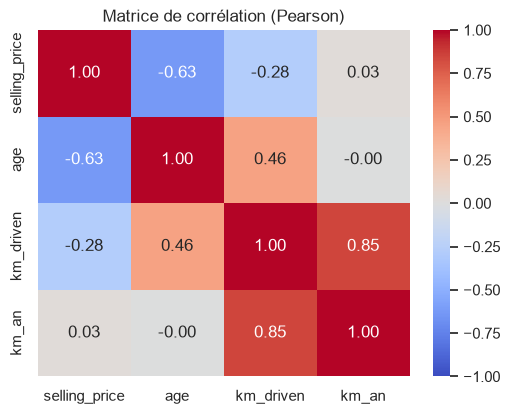

Corrélation de Spearman avec le prix :
selling_price    1.00
age             -0.71
km_driven       -0.30
km_an            0.04
Name: selling_price, dtype: float64

=> L'âge est corrélé au prix à -0.71 et le kilométrage à -0.30.


In [10]:
num = df[['selling_price', 'age', 'km_driven', 'km_an']]

plt.figure(figsize=(6, 4.5))
sns.heatmap(num.corr(method='pearson'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matrice de corrélation (Pearson)')
plt.show()

sp = num.corr(method='spearman')['selling_price']
print('Corrélation de Spearman avec le prix :')
print(sp.round(2))
print(f"\n=> L'âge est corrélé au prix à {sp['age']:.2f} et le kilométrage à {sp['km_driven']:.2f}.")

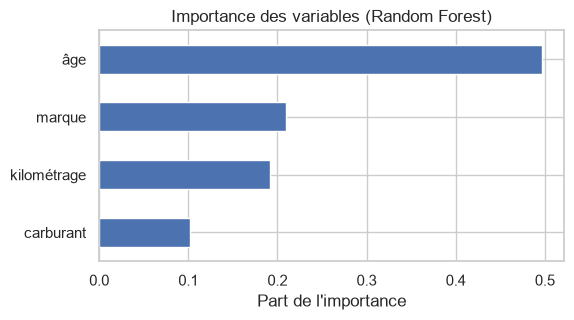

âge            49.7 %
marque         21.0 %
kilométrage    19.2 %
carburant      10.1 %
dtype: str


In [11]:
X = pd.get_dummies(df[['age', 'km_driven', 'marque', 'fuel']], drop_first=True)
y = df['selling_price']

rf = RandomForestRegressor(n_estimators=200, random_state=42).fit(X, y)
imp = pd.Series(rf.feature_importances_, index=X.columns)

def variable_mere(col):
    if col.startswith('marque_'): return 'marque'
    if col.startswith('fuel_'):   return 'carburant'
    return {'age': 'âge', 'km_driven': 'kilométrage'}[col]

imp_groupe = imp.groupby(variable_mere).sum().sort_values()

imp_groupe.plot(kind='barh', figsize=(6, 3))
plt.title("Importance des variables (Random Forest)")
plt.xlabel("Part de l'importance")
plt.show()

print((imp_groupe.sort_values(ascending=False) * 100).round(1).astype(str) + ' %')

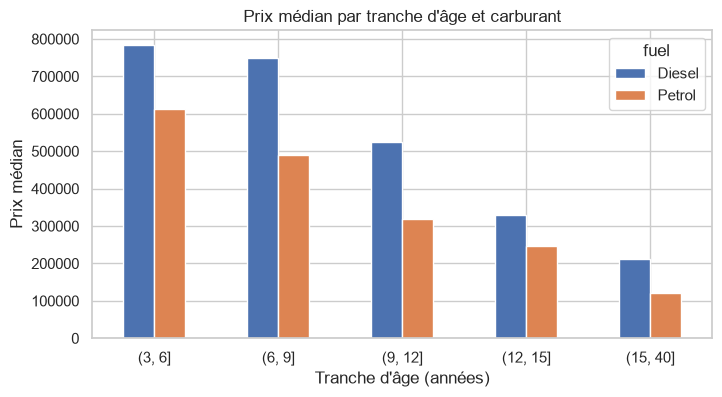

fuel            Diesel     Petrol  écart Diesel vs Essence (%)
tranche_age                                                   
(3, 6]      784,000.00 614,000.00                        27.70
(6, 9]      750,000.00 490,000.00                        53.10
(9, 12]     525,000.00 320,000.00                        64.10
(12, 15]    330,000.00 247,000.00                        33.60
(15, 40]    211,000.00 120,000.00                        75.80

À âge et kilométrage égaux, une essence se vend -36.1 % par rapport à un diesel (p-value = 6.99e-125).


In [12]:
d = df[df['fuel'].isin(['Diesel', 'Petrol'])].copy()
d['tranche_age'] = pd.cut(d['age'], bins=[0, 3, 6, 9, 12, 15, 40])

comp = d.groupby(['tranche_age', 'fuel'], observed=True)['selling_price'].median().unstack()
comp['écart Diesel vs Essence (%)'] = (comp['Diesel'] / comp['Petrol'] - 1) * 100

comp[['Diesel', 'Petrol']].plot(kind='bar', figsize=(8, 4))
plt.title("Prix médian par tranche d'âge et carburant")
plt.xlabel("Tranche d'âge (années)")
plt.ylabel('Prix médian')
plt.xticks(rotation=0)
plt.show()

print(comp.round(1))

ols = smf.ols('np.log1p(selling_price) ~ age + km_driven + C(fuel)', data=d).fit()
coef = ols.params['C(fuel)[T.Petrol]']
ecart = np.expm1(coef) * 100
print(f"\nÀ âge et kilométrage égaux, une essence se vend {ecart:+.1f} % par rapport à un diesel "
      f"(p-value = {ols.pvalues['C(fuel)[T.Petrol]']:.3g}).")

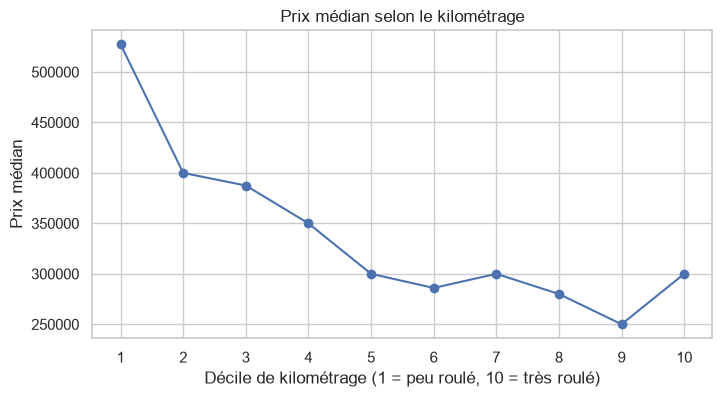

    Prix médian  Variation vs tranche précédente (%)
1    527,500.00                                  NaN
2    400,000.00                               -24.20
3    387,500.00                                -3.10
4    350,000.00                                -9.70
5    300,000.00                               -14.30
6    286,000.00                                -4.70
7    300,000.00                                 4.90
8    280,000.00                                -6.70
9    250,000.00                               -10.70
10   300,000.00                                20.00


In [13]:
df['tranche_km'] = pd.qcut(df['km_driven'], q=10)
courbe = df.groupby('tranche_km', observed=True)['selling_price'].median()

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), courbe.values, marker='o')
plt.xticks(range(1, 11))
plt.xlabel('Décile de kilométrage (1 = peu roulé, 10 = très roulé)')
plt.ylabel('Prix médian')
plt.title('Prix médian selon le kilométrage')
plt.show()

variation = courbe.pct_change() * 100
print(pd.DataFrame({'Prix médian': courbe.values, 'Variation vs tranche précédente (%)': variation.values},
                   index=range(1, 11)).round(1))

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, df['selling_price'], test_size=0.2, random_state=42)
y_train_log = np.log1p(y_train)

modeles = {
    'Régression linéaire': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42),
}

resultats = []
for nom, m in modeles.items():
    m.fit(X_train, y_train_log)
    pred = np.expm1(m.predict(X_test))
    resultats.append({'Modèle': nom,
                      'R² (test)': round(r2_score(y_test, pred), 3),
                      'MAE': round(mean_absolute_error(y_test, pred))})

tableau_modeles = pd.DataFrame(resultats)
tableau_modeles

,Modèle,R² (test),MAE
0,Régression linéaire,0.63,110227
1,Random Forest,0.61,108873
